# 1.3 Binary classification with Decision Forests: HR Job Change

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jauniusc/cvmatch/blob/main/1.3/1_3_hr_job_change_decision_forests.ipynb)

Task 1.3. This notebook is based on the lecturer's notebook **"AdventureWorks DW using TensorFlow Decision Forests"** (A. Laukaitis).
First I explain how the original works, then I redo it with the same Kaggle HR data as in my neural network notebook.

## How the original notebook works

1. **Data.** The same `vTargetMail.csv` (18,484 AdventureWorks customers, target = `BikeBuyer`).
   There is also an `alternative_data` switch: if a file `july4.csv` is uploaded, it is used instead.
2. **Cleaning.** The same ID / personal columns are dropped and `BikeBuyer` is renamed to `target`.
3. **Split 90/10** into train and test only. A random forest doesn't need a separate validation set,
   because it can check itself with **out-of-bag (OOB)** data: every tree is trained on a random sample of rows (with repetition),
   and the rows that were *not* in that sample are used to test that tree.
4. **No preprocessing.** `pd_dataframe_to_tf_dataset` turns the DataFrame into a TensorFlow dataset directly.
   Trees don't need normalization or one-hot encoding: they split on raw numbers (`Age > 40`) and on categories (`Region in {Pacific}`).
5. **Model.** `RandomForestModel(num_trees=10, max_depth=15)`: 10 decision trees, each at most 15 levels deep.
   Every tree votes, and the prediction is the share of trees that voted "yes".
6. **Train and evaluate.** Training takes less than a second. Test accuracy is **~0.81**, better than the neural network (~0.75) on the same data.
7. **Training logs.** Plots OOB accuracy and log loss against the number of trees, to see if more trees help.
8. **Tree plot.** `plot_model_in_colab` draws one tree from the forest, so you can follow the questions it asks.
9. **Inference.** Saves the model, loads it as a `TFSMLayer` and predicts for one new customer: `0.9` = 9 of 10 trees said "yes".
10. **dtreeviz.** The last part tries to draw a tree with the `dtreeviz` library, but that code is commented out.

### Why I use YDF instead of `tensorflow_decision_forests`
The last version of `tensorflow_decision_forests` (1.12, March 2025) only has packages for Python 3.9–3.12,
and Colab now runs Python 3.13, so `pip install tensorflow_decision_forests` no longer works there.
TF-DF is built on top of **YDF (Yggdrasil Decision Forests)**, and Google now recommends YDF as its successor.
It has the same learners (Random Forest, Gradient Boosted Trees) and works with pandas directly,
so the steps of the notebook stay the same, only the function names are a bit different:

| Original (TF-DF) | My version (YDF) |
|---|---|
| `tfdf.keras.pd_dataframe_to_tf_dataset(train, label='target')` | not needed, YDF reads the DataFrame |
| `tfdf.keras.RandomForestModel(num_trees=10, max_depth=15)` + `fit` | `ydf.RandomForestLearner(label='target', num_trees=10, max_depth=15).train(train)` |
| `model.evaluate(test_ds)` | `model.evaluate(test)` |
| `model.make_inspector().training_logs()` | `model.out_of_bag_evaluations()` |
| `tfdf.model_plotter.plot_model_in_colab(model, tree_idx=0)` | `model.plot_tree(tree_idx=0)` |
| `model.save(...)` / `TFSMLayer(...)` | `model.save(...)` / `ydf.load_model(...)` |

## My data
The same Kaggle dataset as in my neural network notebook:
[HR Analytics: Job Change of Data Scientists](https://www.kaggle.com/datasets/arashnic/hr-analytics-job-change-of-data-scientists).
`target = 1` means the candidate is looking for a new job.

In [1]:
%pip install -q ydf

Note: you may need to restart the kernel to use updated packages.


---
## Step 1. From the CSV file to 2 DataFrames: training and test

In [2]:
import os
import pandas as pd

local_path = '../data/hr_job_change/aug_train.csv'
github_url = 'https://raw.githubusercontent.com/jauniusc/cvmatch/main/data/hr_job_change/aug_train.csv'
csv_path = local_path if os.path.exists(local_path) else github_url

df = pd.read_csv(csv_path)
print("The dataframe has {} rows and {} columns.".format(df.shape[0], df.shape[1]))
df[0:5]

The dataframe has 19158 rows and 14 columns.


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


### Remove attributes we don't need
The same as in the NN notebook: drop `enrollee_id` and `city`, make `target` an int.
Unlike the neural network, I **don't fill missing values**: decision trees in YDF can work with missing values themselves.

In [3]:
df = df.drop(columns=['enrollee_id', 'city'])
df['target'] = df['target'].astype('int64')
print(df.iloc[0])

city_development_index                       0.92
gender                                       Male
relevent_experience       Has relevent experience
enrolled_university                 no_enrollment
education_level                          Graduate
major_discipline                             STEM
experience                                    >20
company_size                                  NaN
company_type                                  NaN
last_new_job                                    1
training_hours                                 36
target                                          1
Name: 0, dtype: object


### Split into training and test sets (90:10)

In [4]:
df = df.sample(frac=1, random_state=42)
train = df.iloc[:int(0.9 * len(df))]
test = df.iloc[int(0.9 * len(df)):]

print(len(train), 'training examples')
print(len(test), 'test examples')

17242 training examples
1916 test examples


---
## Step 2. Model
Same settings as the original: 10 trees, max depth 15.
(YDF may print a warning that `experience` looks like numbers. That's because of values like `>20` and `<1`, I keep it as a category like in the NN notebook.)

In [5]:
import ydf

model_1 = ydf.RandomForestLearner(label='target', num_trees=10, max_depth=15).train(train)

[Warning] Column 'experience' is detected as CATEGORICAL but its values look like numbers (e.g., b'20, 8, 14'). Should the column not be NUMERICAL instead? If so, feed numerical values instead of strings or objects.


Train model on 17242 examples


Model trained in 0:00:00.043989


---
## Step 3. Evaluate ⚖️

In [6]:
evaluation = model_1.evaluate(test)
baseline = 1 - test['target'].mean()

print(f"Test accuracy: {evaluation.accuracy:.4f}")
print(f"Test AUC:      {evaluation.characteristics[0].roc_auc:.4f}")
print(f"Baseline (always 0) accuracy: {baseline:.4f}")

Test accuracy: 0.7850
Test AUC:      0.7876
Baseline (always 0) accuracy: 0.7516


YDF can also show a full report (accuracy, confusion matrix, ROC curve):

In [7]:
evaluation

Label \ Pred,0,1
0,1295,145
1,267,209


### More trees
Let's try 300 trees and see if it helps.

In [8]:
model_300 = ydf.RandomForestLearner(label='target', num_trees=300, max_depth=15).train(train)
evaluation_300 = model_300.evaluate(test)
print(f"300 trees - test accuracy: {evaluation_300.accuracy:.4f}, AUC: {evaluation_300.characteristics[0].roc_auc:.4f}")

Train model on 17242 examples


Model trained in 0:00:00.940215


300 trees - test accuracy: 0.7923, AUC: 0.8034


### Plotting the training logs 🧾
Out-of-bag accuracy and log loss against the number of trees (like in the original).

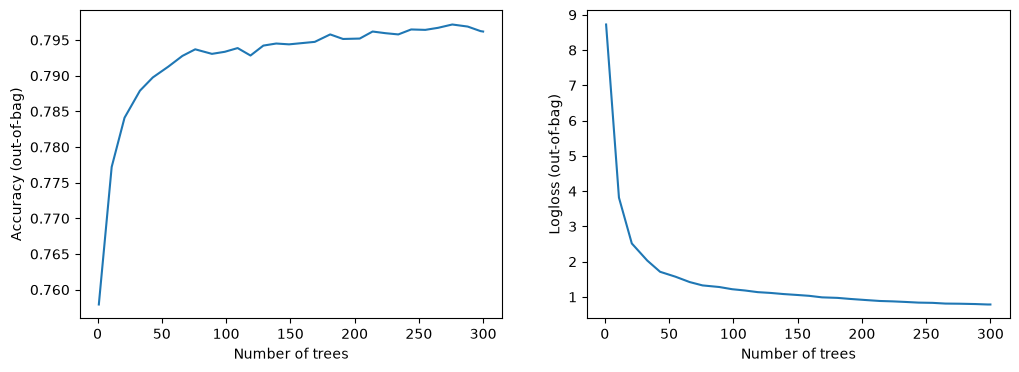

In [9]:
import matplotlib.pyplot as plt

logs = model_300.out_of_bag_evaluations()

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot([log.iteration for log in logs], [log.evaluation.accuracy for log in logs])
plt.xlabel("Number of trees"); plt.ylabel("Accuracy (out-of-bag)")
plt.subplot(1, 2, 2)
plt.plot([log.iteration for log in logs], [log.evaluation.loss for log in logs])
plt.xlabel("Number of trees"); plt.ylabel("Logloss (out-of-bag)")
plt.show()

### Let's choose one tree 🌲 from the forest and plot it
I show only the first 3 levels, otherwise the tree is too big to read.

In [10]:
model_1.plot_tree(tree_idx=0, max_depth=3)

---
## Step 4. Perform inference 🛠
### Save 💾 and load ⚙️

In [11]:
model_300.save('hr_job_change_RandomForestModel_trees300')
reloaded_model = ydf.load_model('hr_job_change_RandomForestModel_trees300')

Loading model from hr_job_change_RandomForestModel_trees300


### New data 🗃️ (the same two candidates as in the NN notebook)

In [12]:
candidates = pd.DataFrame([
    {'city_development_index': 0.62, 'gender': 'Male', 'relevent_experience': 'No relevent experience',
     'enrolled_university': 'Full time course', 'education_level': 'Graduate', 'major_discipline': 'STEM',
     'experience': '2', 'company_size': None, 'company_type': None, 'last_new_job': 'never', 'training_hours': 40},
    {'city_development_index': 0.92, 'gender': 'Female', 'relevent_experience': 'Has relevent experience',
     'enrolled_university': 'no_enrollment', 'education_level': 'Masters', 'major_discipline': 'STEM',
     'experience': '>20', 'company_size': '10000+', 'company_type': 'Pvt Ltd', 'last_new_job': '4', 'training_hours': 20},
], index=['Junior, studying full time', 'Senior in a big company'])
candidates

,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours
"Junior, studying full time",0.62,Male,No relevent experience,Full time course,Graduate,STEM,2,NaN,NaN,never,40
Senior in a big company,0.92,Female,Has relevent experience,no_enrollment,Masters,STEM,>20,10000+,Pvt Ltd,4,20


### Predict 🔮

In [13]:
predictions = reloaded_model.predict(candidates)
for name, prob in zip(candidates.index, predictions):
  print(f"{name}: the likelihood that this candidate is LOOKING FOR A NEW JOB is {100 * prob:.1f} percent.")

Junior, studying full time: the likelihood that this candidate is LOOKING FOR A NEW JOB is 67.0 percent.
Senior in a big company: the likelihood that this candidate is LOOKING FOR A NEW JOB is 3.7 percent.


---
## Results and conclusions

| Model | Test accuracy | Test AUC |
|---|---|---|
| Always answer 0 (baseline) | 0.752 | 0.5 |
| Neural network (my NN notebook) | 0.765 | 0.794 |
| Random Forest, 10 trees | 0.785 | 0.788 |
| **Random Forest, 300 trees** | **0.792** | **0.803** |

- The trees are a bit better than the neural network, like in the original notebook, and they need no preprocessing.
- More trees help only up to ~60 trees, after that the out-of-bag accuracy stays almost the same.
- The predictions are similar to the NN: junior ~67%, senior ~4%.